# Negative Binomial Distribution

Companion notebook for the [negative binomial note](../../notes/random_variables_and_distributions/discrete/negative_binomial_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/negative_binomial_distribution.md).

In the notes, $X$ is the trial number of the $r$-th success, $X\in\{r,r+1,\dots\}$:

$$P(X=k)=\binom{k-1}{r-1}p^r(1-p)^{k-r},\qquad E[X]=\frac rp,\qquad \operatorname{Var}(X)=\frac{r(1-p)}{p^2}.$$

`scipy.stats.nbinom(r, p)` instead counts the failures $Y=X-r$ before the $r$-th success, so we must shift by $r$ when comparing.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

In [2]:
class NegativeBinomialDistribution:
    """X = total number of trials needed for r successes, X in {r, r+1, ...}."""

    def __init__(self, r, p):
        self.r = r
        self.p = p

    def pmf(self, k):
        k = np.asarray(k)
        return np.array([
            math.comb(int(i) - 1, self.r - 1) * self.p**self.r * (1 - self.p) ** (i - self.r)
            if i >= self.r else 0.0
            for i in k.ravel()
        ]).reshape(k.shape)

    def cdf(self, k):
        k = np.asarray(k)
        grid = np.arange(self.r, int(k.max()) + 1)
        cum = np.cumsum(self.pmf(grid))
        return np.array([cum[int(i) - self.r] if i >= self.r else 0.0 for i in k.ravel()]).reshape(k.shape)

    def mean(self):
        return self.r / self.p

    def var(self):
        return self.r * (1 - self.p) / self.p**2

## Check against `scipy.stats`

The argument passed to scipy is `k - r` (number of failures).

In [3]:
r1, p1 = 5, 0.5
r2, p2 = 3, 0.7
k1 = np.arange(r1, r1 + 30)
k2 = np.arange(r2, r2 + 30)
d1, d2 = NegativeBinomialDistribution(r1, p1), NegativeBinomialDistribution(r2, p2)

pmf1, pmf2 = stats.nbinom.pmf(k1 - r1, r1, p1), stats.nbinom.pmf(k2 - r2, r2, p2)
cdf1, cdf2 = stats.nbinom.cdf(k1 - r1, r1, p1), stats.nbinom.cdf(k2 - r2, r2, p2)
print("PMF matches:", np.allclose(d1.pmf(k1), pmf1), np.allclose(d2.pmf(k2), pmf2))
print("CDF matches:", np.allclose(d1.cdf(k1), cdf1), np.allclose(d2.cdf(k2), cdf2))
print("Means (theory):", d1.mean(), round(d2.mean(), 3), "| variances:", d1.var(), round(d2.var(), 3))

PMF matches: True True
CDF matches: True True
Means (theory): 10.0 4.286 | variances: 10.0 1.837


## Shape of the PMF and CDF

The support starts at $r$. The PMF is the distribution of a sum of $r$ independent geometric waiting times, so larger $r$ moves it to the right and makes it more bell-shaped.

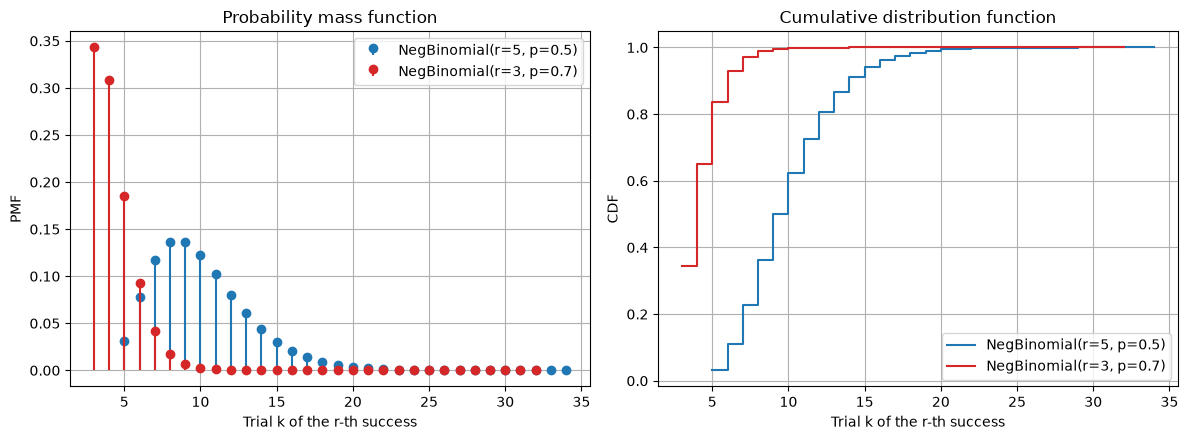

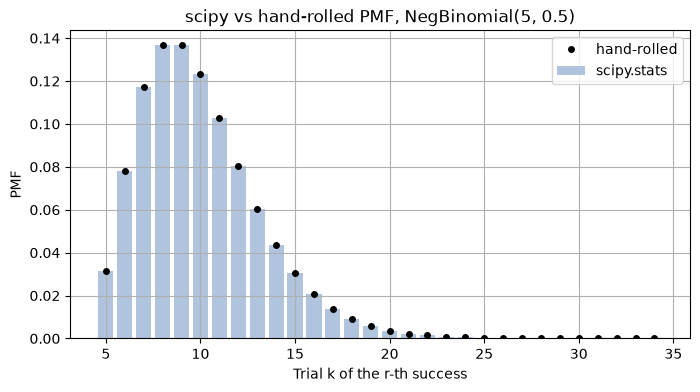

In [4]:
def plot_pmf_cdf(x1, pmf1, cdf1, label1, x2, pmf2, cdf2, label2, xlabel):
    """PMF (stem) and CDF (step) of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.stem(x1, pmf1, basefmt=" ", linefmt="C0-", markerfmt="C0o", label=label1)
    ax1.stem(x2, pmf2, basefmt=" ", linefmt="C3-", markerfmt="C3o", label=label2)
    ax1.set(xlabel=xlabel, ylabel="PMF", title="Probability mass function")
    ax2.step(x1, cdf1, where="post", color="C0", label=label1)
    ax2.step(x2, cdf2, where="post", color="C3", label=label2)
    ax2.set(xlabel=xlabel, ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, xlabel, title):
    """Hand-rolled values (dots) on top of the scipy.stats values (bars)."""
    plt.figure(figsize=(8, 4))
    plt.bar(x, ref, color="lightsteelblue", label="scipy.stats")
    plt.plot(x, custom, "ko", markersize=4, label="hand-rolled")
    plt.xlabel(xlabel)
    plt.ylabel("PMF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pmf_cdf(k1, pmf1, cdf1, f"NegBinomial(r={r1}, p={p1})",
             k2, pmf2, cdf2, f"NegBinomial(r={r2}, p={p2})", "Trial k of the r-th success")
plot_overlay(k1, pmf1, d1.pmf(k1), "Trial k of the r-th success", "scipy vs hand-rolled PMF, NegBinomial(5, 0.5)")

## Worked example: quality control

From the note: defect probability $0.1$ and inspection continues until $r=5$ defectives are found. The correct value of $P(X=20)$ is about $0.0080$.

In [5]:
qc = NegativeBinomialDistribution(5, 0.1)
print(f"P(X = 20) = {qc.pmf(20):.5f}   scipy: {stats.nbinom.pmf(15, 5, 0.1):.5f}")
print(f"E[X] = {qc.mean():.1f},  Var(X) = {qc.var():.1f},  SD = {math.sqrt(qc.var()):.2f}")

# Relation to the binomial: X <= k  <=>  at least r successes in the first k trials
k = 40
print(f"P(X <= {k}) = {qc.cdf(k):.5f}   P(Binomial({k}, 0.1) >= 5) = {stats.binom.sf(4, k, 0.1):.5f}")

P(X = 20) = 0.00798   scipy: 0.00798
E[X] = 50.0,  Var(X) = 450.0,  SD = 21.21
P(X <= 40) = 0.37098   P(Binomial(40, 0.1) >= 5) = 0.37098


## Simulation versus theory

A negative-binomial draw is the sum of $r$ geometric draws. We simulate both ways: with `rng.negative_binomial` (failures, then add $r$) and with sums of geometrics.

negative_binomial + r  mean 9.999 (theory 10.0)   var 10.007 (theory 10.0)
sum of geometrics      mean 9.999 (theory 10.0)   var 10.007 (theory 10.0)


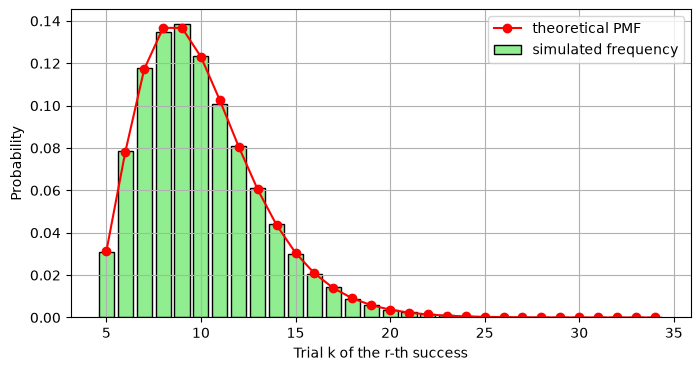

In [6]:
n = 100_000
sample_a = rng.negative_binomial(r1, p1, size=n) + r1          # failures + r = trials
sample_b = rng.geometric(p1, size=(n, r1)).sum(axis=1)         # sum of r geometrics
for name, s in [("negative_binomial + r", sample_a), ("sum of geometrics", sample_b)]:
    print(f"{name:22s} mean {s.mean():.3f} (theory {d1.mean():.1f})   var {s.var():.3f} (theory {d1.var():.1f})")

freq = np.bincount(sample_a, minlength=r1 + 30)[r1:r1 + 30] / n
plt.figure(figsize=(8, 4))
plt.bar(k1, freq, color="lightgreen", edgecolor="black", label="simulated frequency")
plt.plot(k1, d1.pmf(k1), "ro-", label="theoretical PMF")
plt.xlabel("Trial k of the r-th success")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* The note's convention (total trials) differs from scipy's (failures); always shift by $r$.
* $X$ is a sum of $r$ geometric variables, hence mean $r/p$ and variance $r(1-p)/p^2$.
* $P(X\le k)=P(\text{Binomial}(k,p)\ge r)$.